In [31]:
%matplotlib notebook
import numpy as np

from scipy.special import comb

from matplotlib import pyplot as plt

### Experimentally calculated data

In [32]:
occ_strings = {
    'H2_reduced': {
        2: '1 4 2 4 1',
        3: '1 6 6 12 3',
        4: '1 8 12 24 6',
        5: '1 10 20 40 10',
        6: '1 12 30 60 15',
        7: '1 14 42 84 21',
        8: '1 16 56 112 28',
        9: '1 18 72 144 36',
        10: '1 20 90 180 45',
        11: '1 22 110 220 55',
    },
    'H2': {
        2: '1 8 28 24 54 24 28 8 1',
        3: '1 12 66 72 162 72 84 24 3',
        4: '1 16 120 144 324 144 168 48 6',
        5: '1 20 190 240 540 240 280 80 10',
        6: '1 24 276 360 810 360 420 120 15',
        7: '1 28 378 504 1134 504 588 168 21',
        8: '1 32 496 672 1512 672 784 224 28',
        9: '1 36 630 864 1944 864 1008 288 36',
        10: '1 40 780 1080 2430 1080 1260 360 45',
    },
    'LiH_reduced': {
        2: '1 20 190 772 2573 6208 12712 20832 30706 36680 40756 36680 30706 20832 12712 6208 2573 772 190 20 1',
        3: '1 30 435 2094 7515 18498 38088 62496 92118 110040 122268 110040 92118 62496 38136 18624 7719 2316 570 60 3',
        4: '1 40 780 4040 14894 36912 76144 124992 184236 220080 244536 220080 184236 124992 76272 37248 15438 4632 1140 120 6',
        5: '1 50 1225 6610 24710 61450 126880 208320 307060 366800 407560 366800 307060 208320 127120 62080 25730 7720 1900 200 10',
        6: '1 60 1770 9804 36963 92112 190296 312480 460590 550200 611340 550200 460590 312480 190680 93120 38595 11580 2850 300 15',
        7: '1 70 2415 13622 51653 128898 266392 437472 644826 770280 855876 770280 644826 437472 266952 130368 54033 16212 3990 420 21',
        8: '1 80 3160 18064 68780 171808 355168 583296 859768 1027040 1141168 1027040 859768 583296 355936 173824 72044 21616 5320 560 28',
        9: '1 90 4005 23130 88344 220842 456624 749952 1105416 1320480 1467216 1320480 1105416 749952 457632 223488 92628 27792 6840 720 36',
        10: '1 100 4950 28820 110345 276000 570760 937440 1381770 1650600 1834020 1650600 1381770 937440 572040 279360 115785 34740 8550 900 45',
    }
}

In [33]:
qubit_nums = {
    'H2_reduced': 2,
    'H2': 4,
    'LiH_reduced': 10,
}

In [34]:
two_local_qubit_nums = {
    'H2_reduced': {
        2: 10,
        3: 24,
        4: 44,
        5: 70,
        6: 102,
        7: 140,
        8: 184,
        9: 234,
        10: 290,
        11: 352,
    },
    'H2': {
        2: 1125,
        3: 3357,
        4: 6700,
        5: 11154,
        6: 16719,
        7: 23395,
        8: 31882,
        9: 40080,
        10: 50089,
    },
}

In [35]:
r_num_qubit_nums = {
    molecule: {
        r_num: qubit_nums[molecule] * r_num
        for r_num in occ_strings[molecule]
    }
    for molecule in qubit_nums
}

### We slightly process our data

In [36]:
occ_arrays = {
    molecule: {
        r_num: np.asarray([int(num) for num in occ_strings[molecule][r_num].split(' ')])
        for r_num in occ_strings[molecule]
    }
    for molecule in occ_strings
}

In [37]:
r_num_localities = {
    molecule: {
        r_num: len(occ_arrays[molecule][r_num]) - 1
        for r_num in occ_arrays[molecule]
    }
    for molecule in occ_arrays
}

## Estimation functions

### Functions to estimate how many terms of different localities there are in Hamiltonian

In [38]:
# # A very conservative estimate: it supposes that all terms of higher locality
# # are such that their reduction can cancel as many terms of lower locality as possible
def cancel_terms(occ_array, r_num_qubit_num, r_num_locality):
    occ_array_len = len(occ_array)
    assert occ_array_len == r_num_locality + 1
    
    max_occ_array = np.copy(occ_array) 
    for idx in range(occ_array_len - 1, 2, -1):
        max_occ_array[idx - 1] += 2 * max_occ_array[idx]
        max_occ_array[idx - 2] += max_occ_array[idx]
        
    for idx in range(1, occ_array_len):
        comb_num = comb(r_num_qubit_num, idx)
        if max_occ_array[idx] > comb_num:
            max_occ_array[idx] = comb_num
            
    min_occ_array = np.copy(occ_array)
    for idx in range(occ_array_len - 1, 2, -1):
        min_occ_array[idx - 1] -= 2 * max_occ_array[idx]
        min_occ_array[idx - 2] -= max_occ_array[idx]
        
    for idx in range(1, occ_array_len):
        min_occ_array[idx] = max(0, min_occ_array[idx])
        
    return min_occ_array

In [39]:
# An estimate assuming that terms do not cancel out
def preserve_terms(occ_array, r_num_qubit_num, r_num_locality):
    return occ_array

### Functions to give a lower bound on how many new qubits may bring terms of different localities

In [40]:
# A very simple and naive estimate of (k-2) for a k-local term
def dumb_term_bounds(r_num_locality):
    return np.asarray(range(r_num_locality + 1)) - 2

In [41]:
# A smarter approach, using recurrent relation
def smart_term_bounds(r_num_locality):
    c_1 = (4.0 + 3 * np.sqrt(2.0)) / 8.0 
    c_2 = (4.0 - 3 * np.sqrt(2.0)) / 8.0 
    l_1 = np.sqrt(2.0)
    l_2 = -l_1
    
    term_bounds = np.zeros(r_num_locality + 1, dtype=int)
    for idx in range(r_num_locality + 1):
        term_bounds[idx] = -2.0 + c_1 * np.power(l_1, idx) + c_2 * np.power(l_2, idx)
        
    return term_bounds

In [42]:
term_treatments = {
    'cancel': cancel_terms,
    'preserve': preserve_terms,
}

In [43]:
term_bounds = {
    'dumb': dumb_term_bounds,
    'smart': smart_term_bounds,
}

In [44]:
est_two_local_qubit_num = {}
for molecule in occ_arrays:
    est_two_local_qubit_num[molecule] = {}
    
    for r_num in occ_arrays[molecule]:
        occ_array = occ_arrays[molecule][r_num]
        est_two_local_qubit_num[molecule][r_num] = {}
        
        for term_treatment in ['cancel', 'preserve']:
            for term_bound in ['dumb', 'smart']:
                est_occ_array = term_treatments[term_treatment](occ_array,
                                                                r_num_qubit_nums[molecule][r_num],
                                                                r_num_localities[molecule][r_num])                
                est_term_bounds = term_bounds[term_bound](r_num_localities[molecule][r_num])
                
                est_two_local_qubit_num[molecule][r_num][f'{term_treatment}, {term_bound}'] = r_num_qubit_nums[molecule][r_num] + np.dot(est_occ_array[3:],
                                                                                                     est_term_bounds[3:])

In [45]:
x_axes = {}
est_data_to_plot = {}

for molecule in est_two_local_qubit_num:
    x_axes[molecule] = {}
    est_data_to_plot[molecule] = {}
    
    for term_treatment in ['cancel', 'preserve']:
        for term_bound in ['dumb', 'smart']:
            key = f'{term_treatment}, {term_bound}'
            
            x_axes[molecule][key] = []
            est_data_to_plot[molecule][key] = []
            for r_num in est_two_local_qubit_num[molecule]:
                x_axes[molecule][key].append(r_num)
                est_data_to_plot[molecule][key].append(est_two_local_qubit_num[molecule][r_num][key])
                
    if molecule in two_local_qubit_nums:
        x_axes[molecule]['real'] = []
        est_data_to_plot[molecule]['real'] = []
        
        for r_num in two_local_qubit_nums[molecule]:
            x_axes[molecule]['real'].append(r_num)
            est_data_to_plot[molecule]['real'].append(two_local_qubit_nums[molecule][r_num])

In [46]:
key_to_label = {
    'cancel, dumb': 'rigorous, simple',
    'cancel, smart': 'rigorous, less simple',
    'preserve, dumb': 'less rigorous, simple',
    'preserve, smart': 'less rigorous, less simple',
    'real': 'Baseline'
}
molecule_to_title = {
    'H2': r'$H_2$, 4 qubits',
    'LiH_reduced': r'$LiH$, 10 qubits',
}

<IPython.core.display.Javascript object>


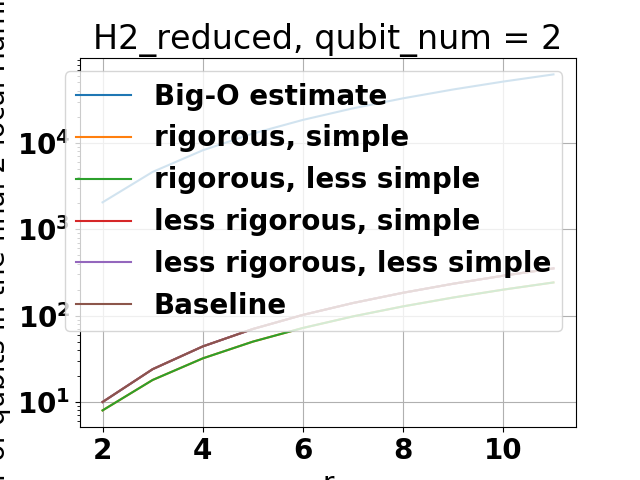

<IPython.core.display.Javascript object>


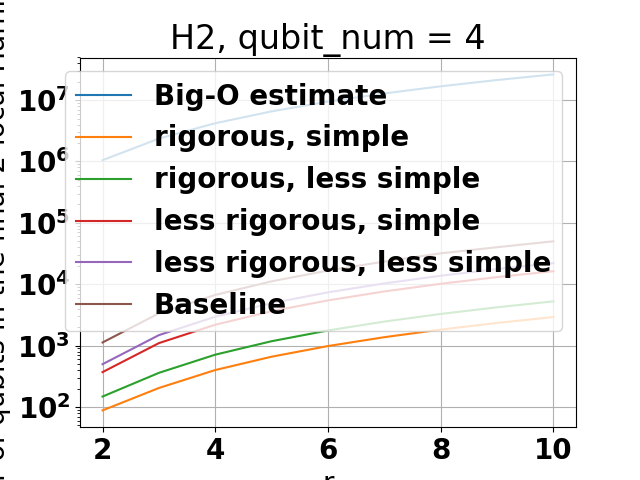

<IPython.core.display.Javascript object>


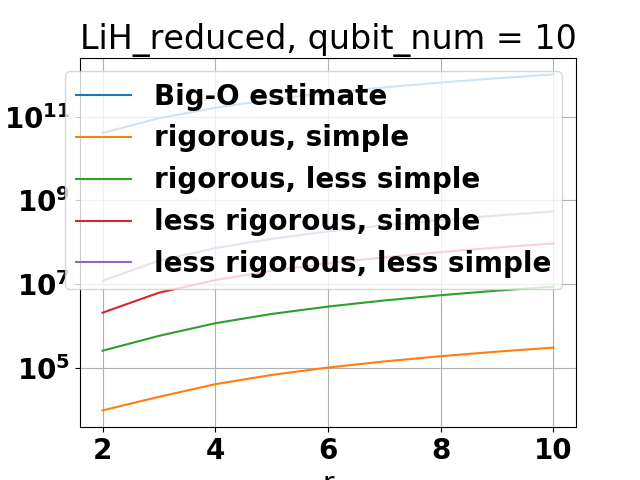

In [47]:
x_axis = np.asarray(range(2, 12))
for molecule in est_data_to_plot:
    fig, ax = plt.subplots()
    ax.grid()
    
    big_o_x_axis = [r_num for r_num in occ_strings[molecule]]
    big_o_y_axis = [(2 ** qubit_nums[molecule]) * (qubit_nums[molecule] ** 7) * (r_num ** 2) for r_num in occ_strings[molecule]]
    ax.plot(big_o_x_axis, big_o_y_axis, label='Big-O estimate')
    
    for key in est_data_to_plot[molecule]:
        ax.plot(x_axes[molecule][key], est_data_to_plot[molecule][key], label=key_to_label[key])
    ax.legend(loc='best')
    ax.set_yscale('log')    
    ax.set_title(f'{molecule}, qubit_num = {qubit_nums[molecule]}')
    ax.set_xlabel(f'r')
    ax.set_ylabel(f'Number of qubits in the final 2-local Hamiltonian')

In [48]:
figsize = 10
linewidth = 3
fs = 20
fontweight=None

In [49]:
import matplotlib
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : fs}

matplotlib.rc('font', **font)

In [50]:
key_to_label = {
    'cancel, smart': r'$\Delta_{\min}$',
    'preserve, smart': r'$\tilde{\Delta}$',
    'real': r'$\Delta$'
}

<IPython.core.display.Javascript object>


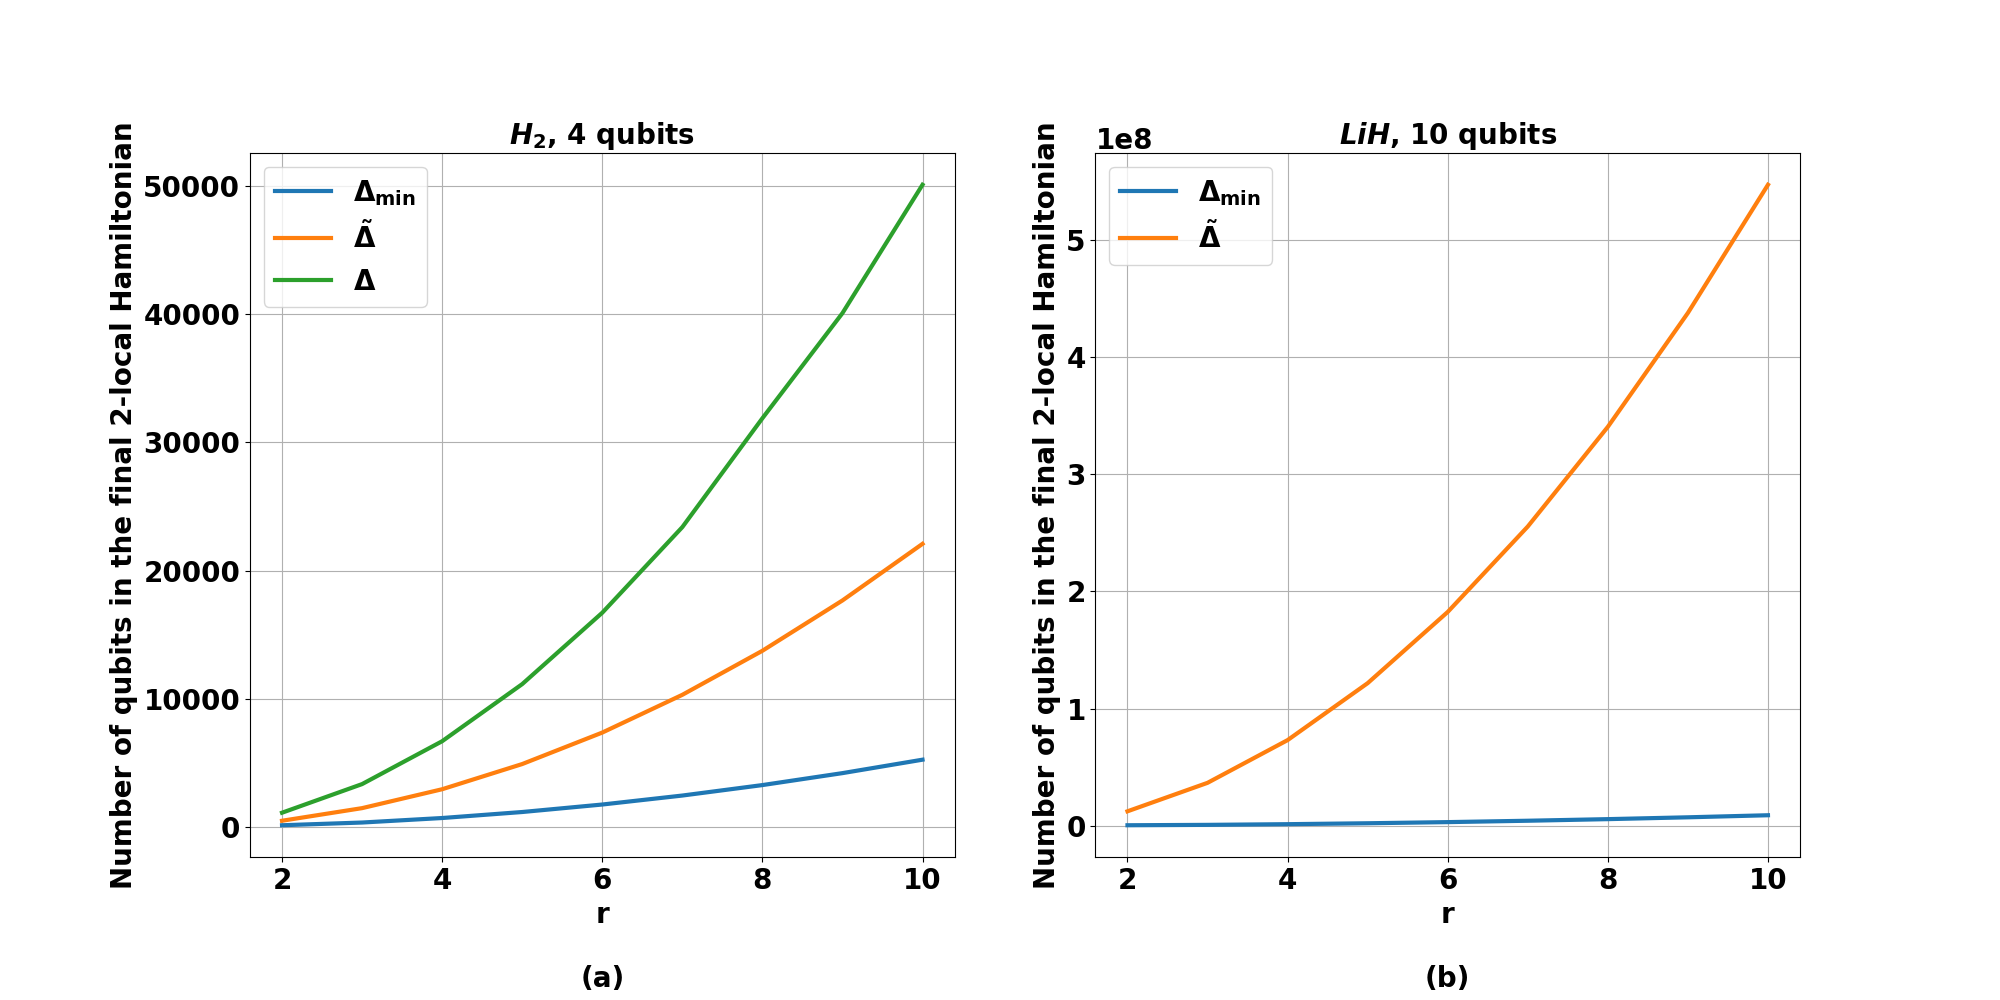

In [51]:
x_axis = np.asarray(range(2, 10))
fig, axes = plt.subplots(1, 2)
fig.set_figwidth(2 * figsize)
fig.set_figheight(figsize)

for idx, molecule in enumerate(['H2', 'LiH_reduced']):    
    axes[idx].grid()
    
#     big_o_x_axis = [r_num for r_num in occ_strings[molecule]]
#     big_o_y_axis = [(2 ** qubit_nums[molecule]) * (qubit_nums[molecule] ** 7) * (r_num ** 2) for r_num in occ_strings[molecule]]
#     axes[idx].plot(big_o_x_axis, big_o_y_axis, label='Big-O estimate')
    
    for key in ['cancel, smart', 'preserve, smart', 'real']:
        if key in est_data_to_plot[molecule]:
            axes[idx].plot(x_axes[molecule][key],
                           est_data_to_plot[molecule][key],
                           label=key_to_label[key],
                           linewidth=linewidth)
            
    axes[idx].legend(loc='best')
    #axes[idx].set_yscale('log')    
    axes[idx].set_title(molecule_to_title[molecule], fontsize=fs, fontweight=fontweight)
    axes[idx].set_xlabel(f'r\n\n' + ('(a)' if idx == 0 else '(b)'), fontsize=fs, fontweight=fontweight)
    axes[idx].set_ylabel(f'Number of qubits in the final 2-local Hamiltonian', fontsize=fs, fontweight=fontweight)
    
    asp = np.diff(axes[idx].get_xlim())[0] / np.diff(axes[idx].get_ylim())[0]
    axes[idx].set_aspect(asp)
fig.savefig(f'locality_investigation.pdf', format='pdf', dpi=300)

In [52]:
molecule_to_linestyle = {
    'H2': '--',
    'LiH_reduced': '-',
}
key_to_marker = {
    'real': 'o',
    'cancel, smart': 's',
    'preserve, smart': 'v',
}
key_to_color = {
    'real': 'xkcd:rose pink',
    'cancel, smart': 'xkcd:dark sky blue',
    'preserve, smart': 'xkcd:apricot'
}
molecule_to_loc = {
    'H2': 'lower right',
    'LiH_reduced': 'upper right'
}
ms=10

<IPython.core.display.Javascript object>


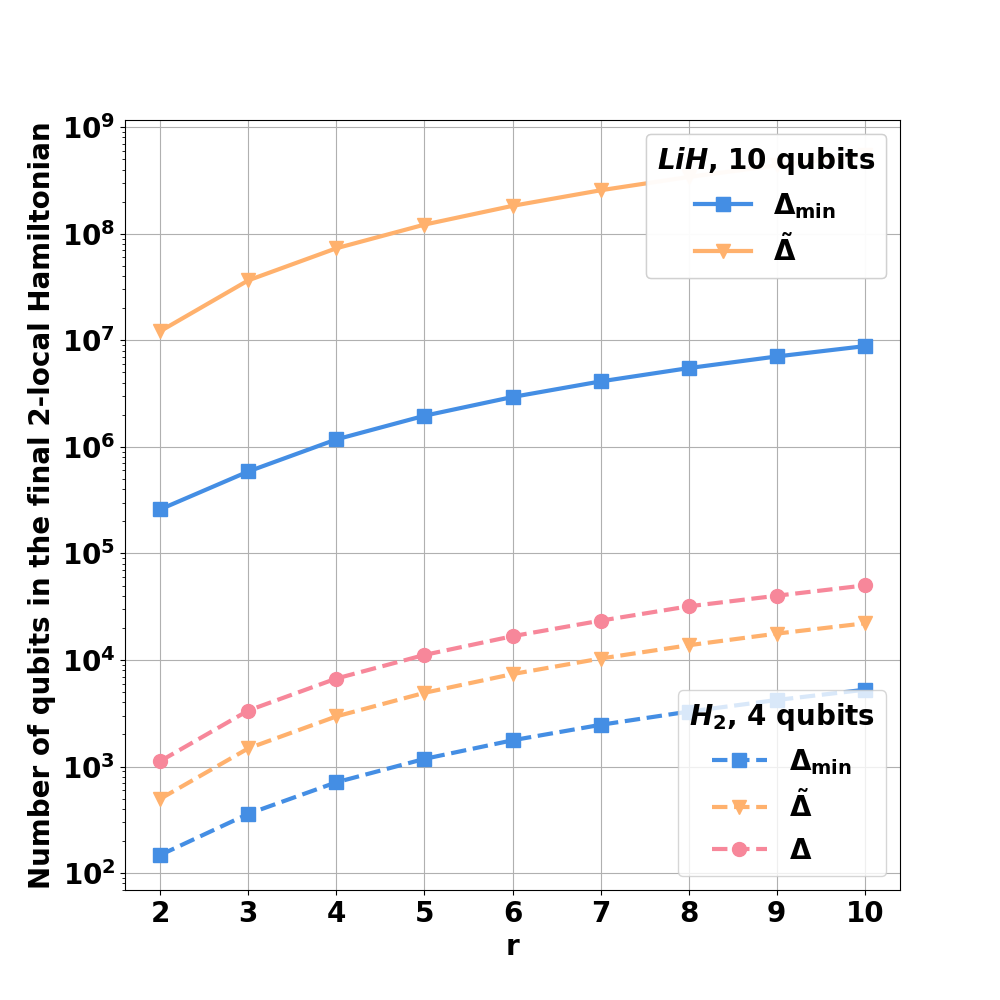

In [53]:
x_axis = np.asarray(range(2, 10))
fig, ax = plt.subplots()
fig.set_figwidth(figsize)
fig.set_figheight(figsize)
ax.grid()

for idx, molecule in enumerate(['H2', 'LiH_reduced']):    
    lines = []    
    for key in ['cancel, smart', 'preserve, smart', 'real']:
        if key in est_data_to_plot[molecule]:
            line, = ax.plot(x_axes[molecule][key],
                           est_data_to_plot[molecule][key],
                           label=key_to_label[key],
                           linewidth=linewidth,
                           linestyle=molecule_to_linestyle[molecule],
                           marker=key_to_marker[key],
                           color=key_to_color[key],
                           ms=ms)
            lines.append(line)
    molecule_legend = plt.legend(handles=lines, loc=molecule_to_loc[molecule], title=molecule_to_title[molecule])
    plt.gca().add_artist(molecule_legend)
            
#ax.legend(loc='best', title='H2')
ax.set_yscale('log')    
#ax.set_title(molecule_to_title[molecule], fontsize=fs, fontweight=fontweight)
ax.set_xlabel(f'r', fontsize=fs, fontweight=fontweight)
ax.set_ylabel(f'Number of qubits in the final 2-local Hamiltonian', fontsize=fs, fontweight=fontweight)
fig.savefig(f'locality_investigation.pdf', format='pdf', dpi=300)